<a href="https://colab.research.google.com/github/pmash634/Telco-churned-cutomers-project-/blob/main/Copy_of_churn_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# uploading the dataset
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [ ]:
df.describe()
df.info()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['TotalCharges'].dtype
df['TotalCharges'].isna().sum()

np.int64(0)

In [ ]:

df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
df['TotalCharges'] = df['TotalCharges'].astype(float)

In [ ]:
df['customerID'].duplicated().sum()

np.int64(0)

In [ ]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [ ]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [ ]:
df['tenure'].corr(df['TotalCharges'])

np.float64(0.8258804609332024)

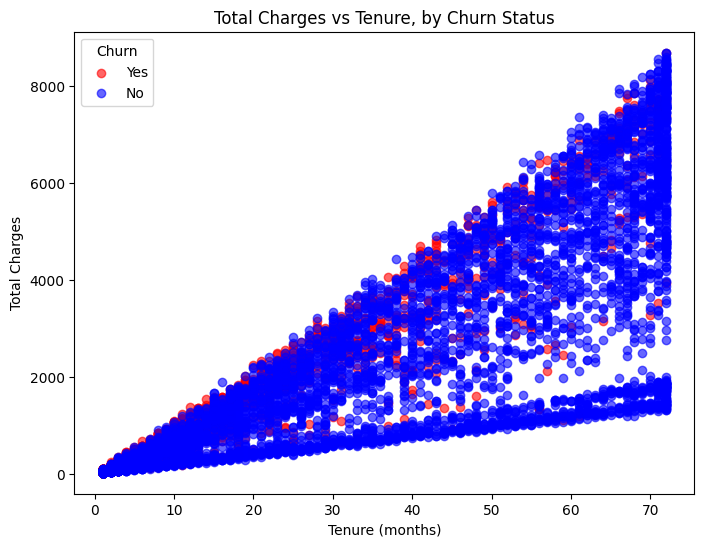

In [ ]:
# Scatter plot of Total Charges vs Tenure, colored by Churn status
# Goal: check whether the tenure-charges relationship differs between churned
# and retained customers, and whether churn clusters at a specific tenure range
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
for status, color in zip(['Yes', 'No'], ['red', 'blue']):
    subset = df[df['Churn'] == status]
    plt.scatter(subset['tenure'], subset['TotalCharges'], label=status, alpha=0.6, color=color)

plt.title('Total Charges vs Tenure, by Churn Status')
plt.xlabel('Tenure (months)')
plt.ylabel('Total Charges')
plt.legend(title='Churn')
plt.show()
# Observation: Total Charges increases linearly with tenure, as expected.
# Churned customers appear concentrated at lower tenure values, suggesting
# customers are more likely to leave early before accumulating high charges.

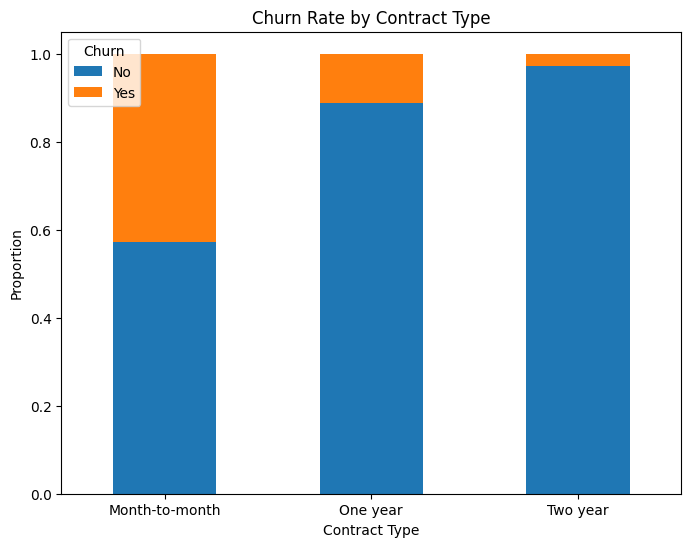

In [ ]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack()

churn_by_contract.plot(kind='bar', stacked=True, figsize=(8,6))
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Proportion')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()
# Finding: Churn rate decreases sharply as contract length increases.
# Month-to-month customers churn far more than one-year customers,
# who in turn churn more than two-year customers.
# This suggests contract type is one of the strongest predictors of churn,
# likely because month-to-month customers face no penalty for leaving.

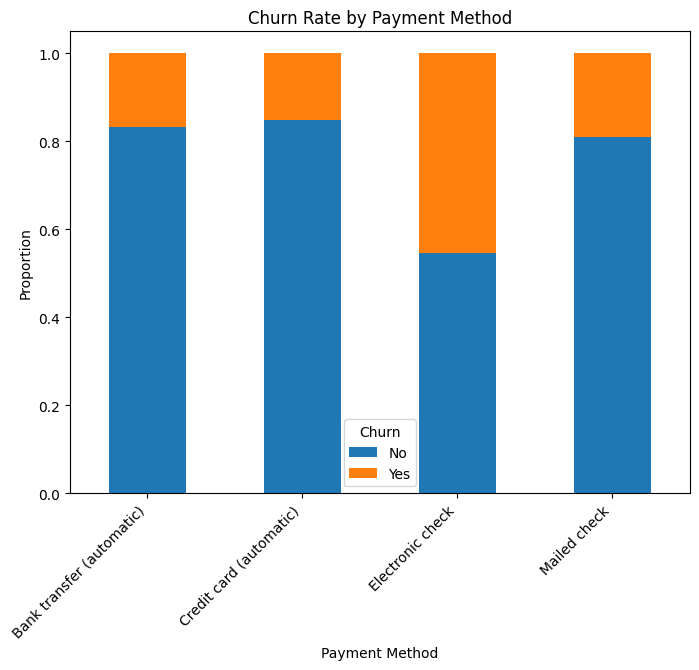

In [ ]:
payment_churn = df.groupby('PaymentMethod')['Churn'].value_counts(normalize=True).unstack()

payment_churn.plot(kind='bar', stacked=True, figsize=(8,6))
plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Proportion')
plt.legend(title='Churn')
plt.xticks(rotation=45, ha='right')
plt.show()
# Finding: Customers paying by electronic check churn at a noticeably higher
# rate than those using automatic payment methods (bank transfer, credit card)
# or mailed check. This may reflect less engagement/commitment among
# electronic check users, or friction in the manual payment process.

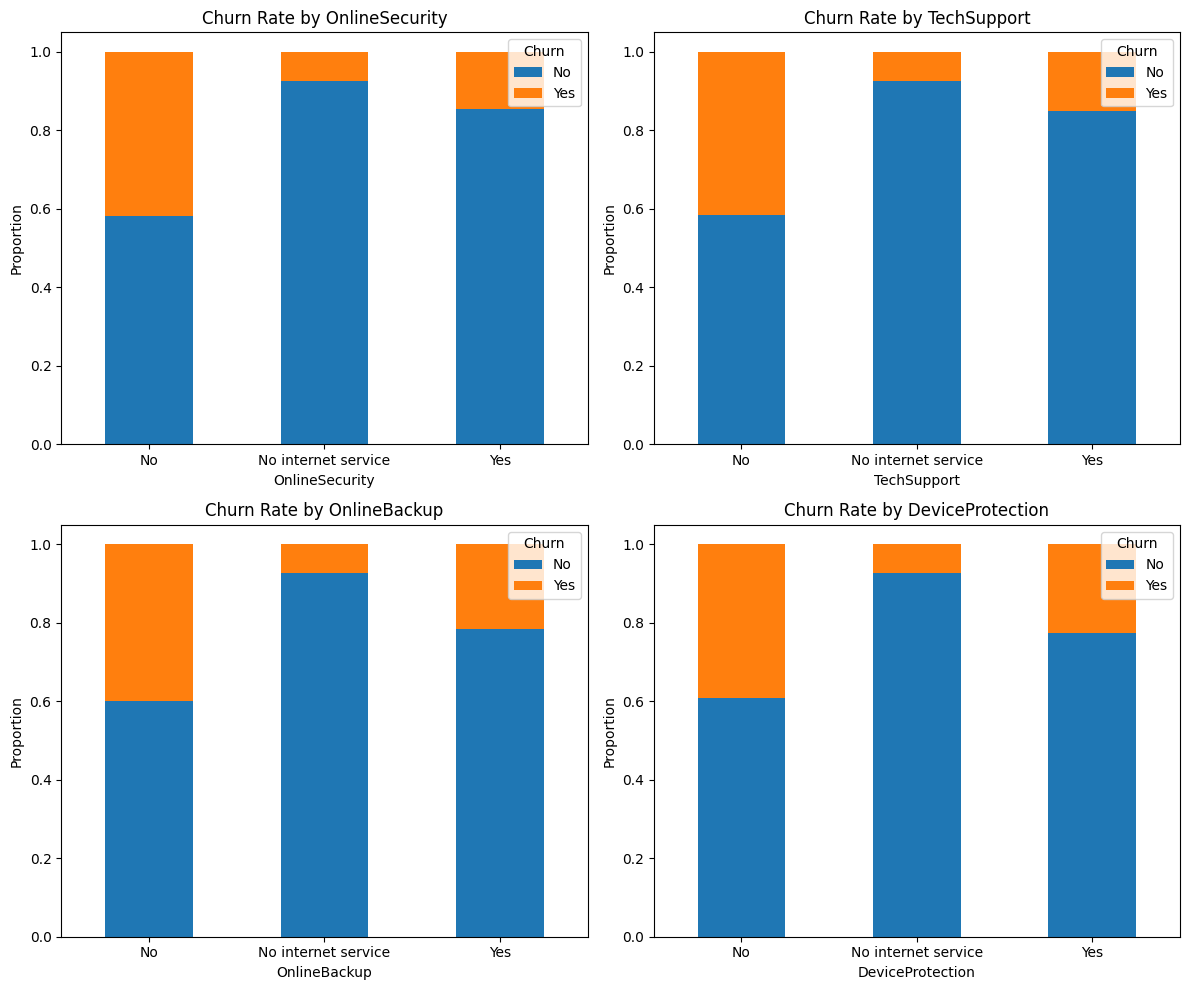

In [ ]:
addon_cols = ['OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection']

fig, axes = plt.subplots(2, 2, figsize=(12,10))
axes = axes.flatten()

for i, col in enumerate(addon_cols):
    churn_by_addon = df.groupby(col)['Churn'].value_counts(normalize=True).unstack()
    churn_by_addon.plot(kind='bar', stacked=True, ax=axes[i])
    axes[i].set_title(f'Churn Rate by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Proportion')
    axes[i].legend(title='Churn')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()
# Finding: Customers without OnlineSecurity, TechSupport, OnlineBackup, or
# DeviceProtection churn more than those with these add-ons. This suggests
# add-on services increase customer investment/stickiness, reducing churn.

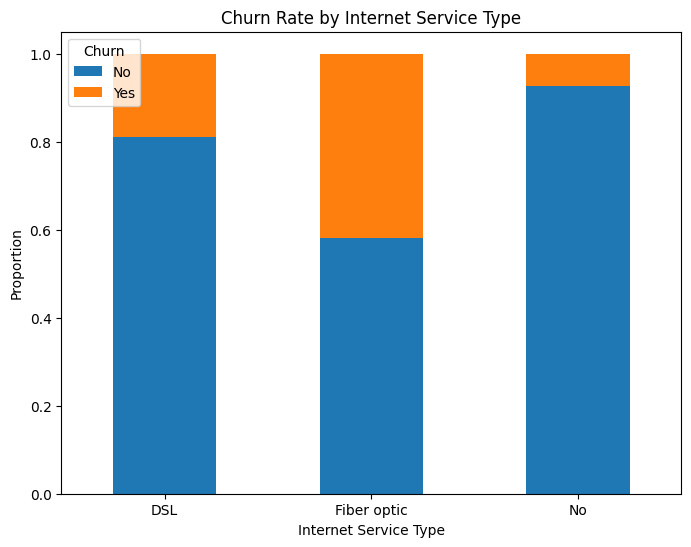

In [ ]:
internet_churn = df.groupby('InternetService')['Churn'].value_counts(normalize=True).unstack()

internet_churn.plot(kind='bar', stacked=True, figsize=(8,6))
plt.title('Churn Rate by Internet Service Type')
plt.xlabel('Internet Service Type')
plt.ylabel('Proportion')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()

In [ ]:
df.groupby('InternetService')['MonthlyCharges'].mean()
# Finding: Fiber optic customers churn more than DSL or no-internet customers.
# This may be partly explained by price: fiber optic averages $91/month in
# MonthlyCharges vs. $58/month for DSL. Higher cost could make fiber customers
# more price-sensitive and more likely to switch providers, though other
# factors (e.g. overlap with month-to-month contracts) may also contribute.

,MonthlyCharges
InternetService,
DSL,58.102169
Fiber optic,91.500129
No,21.079194


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.duplicated().sum()

np.int64(0)

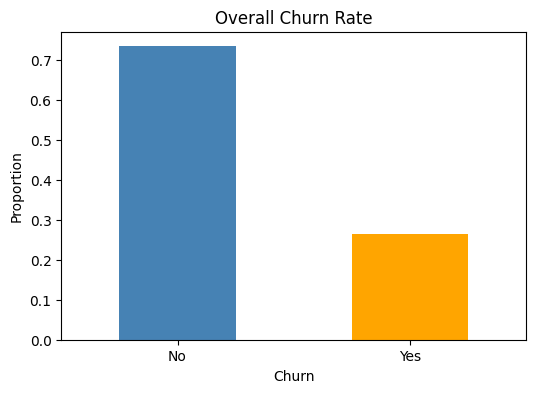

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [ ]:
churn_counts = df['Churn'].value_counts(normalize=True)
churn_counts.plot(kind='bar', color=['steelblue', 'orange'], figsize=(6,4))
plt.title('Overall Churn Rate')
plt.xlabel('Churn')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

print(churn_counts)
# Finding: Only about 26.5% of customers churned, while the majority (73.5%)
# stayed. This confirms churn is the minority class in this dataset, and
# gives a baseline to compare against — e.g. a group with churn above
# ~26.5% churns more than average, and a group below it churns less.

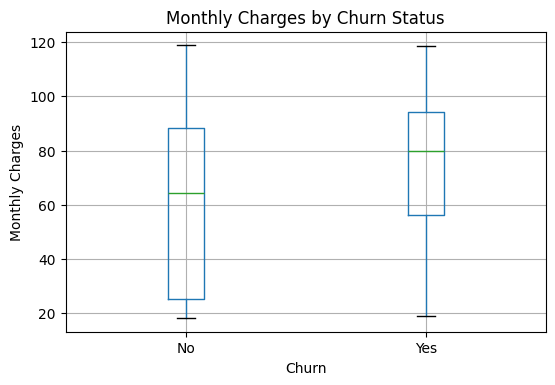

In [ ]:
df.boxplot(column='MonthlyCharges', by='Churn', figsize=(6,4))
plt.title('Monthly Charges by Churn Status')
plt.suptitle('')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()
# Finding: Churned customers have a higher median MonthlyCharges than
# customers who stayed, suggesting cost is a factor in churn decisions.
# This aligns with earlier findings — month-to-month contracts and
# customers without add-ons (who also churn more) likely pay
# proportionally more for the value they perceive, making them more
# price-sensitive and quicker to leave.

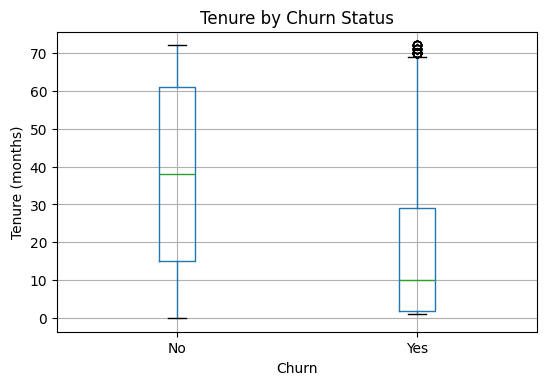

In [ ]:
df.boxplot(column='tenure', by='Churn', figsize=(6,4))
plt.title('Tenure by Churn Status')
plt.suptitle('')
plt.xlabel('Churn')
plt.ylabel('Tenure (months)')
plt.show()
# Finding: Customers with a long tenure rarely churn — the churned group
# is concentrated at low tenure values, while customers who stay show a
# much wider spread including many long-tenured customers. This suggests
# the first few months are the highest-risk period for losing a customer,
# and that customers who stick around past a certain point become
# increasingly unlikely to leave.

In [ ]:
df.to_csv('telco_churn_cleaned.csv', index=False)
files.download('telco_churn_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>